# Introduction

This tutorial is based on [this Jupyter notebook](DataProcessing.ipynb). If you haven't worked on it before, please visit it before continuing here.

**Attention** Since 2026, this notebook is considered __obsolete__ as it relies global image feature descriptors such as CEDD and SIFT. I consider them obsolte as current AI-based solution yield a way better performance if you are willing to invest in the needed (hardware) resources.

Furthermore, the originally Java program to compute the global features is currently missing (May 2026).

This notebook cannot be run at this time.

### Exploring the Collection by Visual Content
* reading the feature files takes approx. 12 min
* erklären, woher die CBIR features kommen (https://en.wikipedia.org/wiki/Bag-of-words_model_in_computer_vision)

![Visual Words](img/visword.jpg)

By Masterwaw - Own work, CC BY-SA 3.0, https://commons.wikimedia.org/w/index.php?curid=19645418

Scale-invariant feature transform, reference for local feature detection

![Visual Word Generation](img/visword_generation2.png)

int sampleDocumentsToCreateCodebook = 5000; 
int numberOfClusters = 1000;

next step takes ca. 40 minutes if the raw features are loaded from disk and converted

## Mandatory Configuration of This Notebook


In [1]:
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If you set 'allowDownloads' to True, all images will be downloaded and processed again
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
allowDownloads=False # should be True if you run this for the first time or False if you want to use the provided sample data

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If 'loadMissingData' is set to True, sample files will be downloaded automatically
# This is a RECOMMENDED SETTING as it will take care of a some extra work for you
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
loadMissingData=True

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Download directory used for images etc.
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
downloadDir="./tmp/"

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Directory used for reports etc.
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
reportDir="./reports/"

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Keep original downloaded TIFF images? Otherwise, they will be deleted and only JPEG thumbnails remain after download.
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *

keepTIFFs=False

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If you set 'demoClustering' to False, the clustering steps will take about 2 hours
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
demoClustering=False # should be False if you run this for the first time

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If you set 'allowComputationallyExpensiveCalculations' to True, various time consuming tasks (some of them running
# several hours) will be carried out and not only loaded from pre-computed data files
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
allowComputationallyExpensiveCalculations=True # should be True if you run this for the first time

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Enabling this action activates exact string matching againt name lists
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
allowExactStringMatching=True

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If you set to True, some plots will be saved as PDF documents in ./figures/
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
saveFiguresAsPDF=True

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If you set to True, Google Map API will be used to resolve location names, if False OpenStreetMap will be used
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *i
useGoogleMapsAPI=False
privateGoogleKey='ENTER YOUR KEY HERE' #if you want to use Google, you need a personal key

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If set to True, OpenStreetMap API will be used to fetch spatial names and alternative localized names, should be True at first run
# in case you want to retrieve all data from OSM (will take approx. 40 minutes)
#
# To get you setup fast, the pickelz/ subdirectory contains a ZIP file called "osm_results.zip" that contains cached results.
#
# PLEASE use this archive to relieve the OSM servers.
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
getSpatialNamesFromOSM=False

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If set to True, details per PPN will be saved as separate JSON files in "jsonWebDir"
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
serializePPNLookup2JSON=False
jsonWebDir="./web/data/ppn/"

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If set to True, the raw features created by the Java application will be read from disk and converted for further usage, must be True at first run
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
reinterpretVisualWordRawFeatures=False

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If set to True, a HTTP webserver will be started after all cells have been processed to show the results
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
launchHTTPServer=False




# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Setup of the environment
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *

# The %... is an iPython thing, and is not part of the Python language.
# In this case we're just telling the plotting library to draw things on
# the notebook, instead of on a separate window.
%matplotlib inline

# See all the "as ..." contructs? They're just aliasing the package names.
# That way we can call methods like plt.plot() instead of matplotlib.pyplot.plot().
import numpy as np
import scipy as sp
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
import time
pd.set_option('display.width', 500)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 40)
pd.set_option('display.notebook_repr_html', True)
import seaborn as sns
sns.set_style("whitegrid")
sns.set_context("notebook")

from bs4 import BeautifulSoup
from collections import OrderedDict # provides the ordered dictionary
import re # for regular expressions used below
import urllib # to read from URLs
import requests
import json
import networkx as nx # network analysis
from networkx.readwrite import json_graph
import itertools

import os.path
from datetime import datetime # for time measurement
import time # for time measurement
import sys
import os
import pickle
import subprocess as subp
import gzip
import math
import codecs
import subprocess
import platform
import zipfile
import tqdm
import hashlib

# string distance/similarity functions - names were fixed in jellyfish to be correct (finally)
from jellyfish import jaro_similarity, jaro_winkler_similarity, hamming_distance, levenshtein_distance

import scipy.cluster.hierarchy as scipycluster
from sklearn.feature_extraction.text import TfidfVectorizer

from skimage import io, exposure
from scipy.spatial import distance
# import the k-means algorithm
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import pairwise_distances_argmin,pairwise_distances_argmin_min, pairwise_distances
from sklearn.metrics.pairwise import euclidean_distances

from sentence_transformers import SentenceTransformer

# OAI
from sickle import Sickle

# image handling
from PIL import Image

# geo stuff
import googlemaps
from geopy.distance import geodesic
import geojson as gj

# progress bar
from tqdm import tqdm

# utility functions
# print a line with the current timestamp
def printLog(text):
    now=str(datetime.now())
    print("["+now+"]\t"+text)
    # forces to output the result of the print command immediately, see: http://stackoverflow.com/questions/230751/how-to-flush-output-of-python-print
    sys.stdout.flush()

# serialize an object as a gzipped pickle file
def pickleCompress(fileName,pickledObject):
    printLog("Pickling to '%s'" %fileName)
    f = gzip.open(fileName,'wb')
    pickle.dump(pickledObject,f)
    f.close()
    printLog("Pickling done.")

# load a gzipped pickle file from disk
def pickleDecompress(fileName):
    #restore the object
    printLog("Depickling from '%s'" %fileName)
    f = gzip.open(fileName,'rb')
    pickledObject = pickle.load(f)
    f.close()
    printLog("Depickling done.")
    return pickledObject

# load a file from an URL and save it to a folder
def saveFileFromURL(file_url,output_dir):
    # get the path part of the URL
    path = urllib.parse.urlparse(file_url).path
    # remove the 8bit-inferno.de-specific path part
    file_part=path.replace("/_persistent/","")

    printLog(f"Downloading {file_url} to '{output_dir}/{file_part}'")

    # send a GET request to the URL
    response = requests.get(file_url)
    # check if the request was successful
    if response.status_code == 200:
        # Open a local file in binary write mode
        with open(output_dir+'/'+file_part, 'wb') as file:
            # Write the content of the response to the file
            file.write(response.content)
        printLog("Finished download.")
        return True
    else:
        printLog(f"Failed to download file with HTTP status code: {response.status_code}")
        return False


# global start time: used to check the run time of all cells
globalStartTime = time.process_time()

# create necessary directories
if not os.path.exists(downloadDir):
        os.makedirs(downloadDir)
if not os.path.exists(reportDir):
        os.makedirs(reportDir)
if not os.path.exists("./picklez/"):
        os.makedirs("./picklez/")
if not os.path.exists("./figures/"):
        os.makedirs("./figures/")
if not os.path.exists("./graphs/"):
        os.makedirs("./graphs/")
if not os.path.exists("./graphs/generics/"):
        os.makedirs("./graphs/generics/")
if not os.path.exists("./html/"):
        os.makedirs("./html/")
if not os.path.exists("./web/"):
        os.makedirs("./web/")
if not os.path.exists("./web/qa/"):
        os.makedirs("./web/qa/")
if not os.path.exists("./web/data/"):
        os.makedirs("./web/data/")
if not os.path.exists("./web/data/ppn/"):
        os.makedirs("./web/data/ppn/")
if not os.path.exists("./web/data/layers/"):
        os.makedirs("./web/data/layers/")

/Users/david/src/SBBrowse2018/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1030 22:19:02.451000 63500 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
grpCentury=pickleDecompress('./picklez/grpCentury.picklez')
ppnPerCentury=pickleDecompress("./picklez/ppnPerCentury.picklez")
df4=pickleDecompress('./picklez/df4.picklez')
df4.head()

[2026-10-30 22:19:02.969283]	Depickling from './picklez/grpCentury.picklez'
[2026-10-30 22:19:03.099692]	Depickling done.
[2026-10-30 22:19:03.100090]	Depickling from './picklez/ppnPerCentury.picklez'
[2026-10-30 22:19:03.103807]	Depickling done.
[2026-10-30 22:19:03.104130]	Depickling from './picklez/df4.picklez'
[2026-10-30 22:19:03.222817]	Depickling done.


,title,creator,subject,publisher,type,format,identifier,language,date,coverage,rights,PPN,spatialClean,dateClean,spatialCluster,spatialClusterName,latitude,longitude,century
0,"Collegium Ethicum, In Quo De Summo Hominis Bon...","Liebenthal, Christianus",Historische Drucke,Hampelius,monograph,application/mets+xml,PPN1000000974,lat,1620,Giessae Hessorum,Public Domain Mark 1.0,PPN1000000974,Giessae,1620,,NaN,NaN,NaN,16
1,"Augustini Niphi, Philosophi Suessani De Auguri...","Niphus, Augustinus",Historische Drucke,Egenolphus,monograph,application/mets+xml,PPN100000127X,lat,1614,Marpurgi,Public Domain Mark 1.0,PPN100000127X,Marpurgi,1614,1622,Marpurgi,46.5602870,15.6480467,16
2,Concerto pour la Flûte avec Accompagnement de ...,"Danzi, Franz",Musiknoten,Breitkopf & Härtel,monograph,application/mets+xml,PPN1000006808,NaN,1806,Leipsic,CC BY-NC-SA 4.0 International,PPN1000006808,Leipsic,1806,1092,Leipsic,39.2409266,-75.5167955,18
3,Schuldige Condolentz-Zeilen Womit seinem Gelie...,"Koltemann, Otto Benedict",Historische Drucke,Königliche privil. Buchdruckerey,monograph,application/mets+xml,PPN1000056597,ger,1719,Glückstadt,Public Domain Mark 1.0,PPN1000056597,Glückstadt,1719,230,Glückstadt,53.7879270,9.4238157,17
4,Johann Friedrich Böttchers der Arzney und Wund...,"Böttcher, Johann Friedrich",Historische Drucke,Oehmigke,monograph,application/mets+xml,PPN1000059669,ger,1796,Berlin,Public Domain Mark 1.0,PPN1000059669,Berlin,1796,1659,Berlin,52.5173885,13.3951309,17


In [3]:
df4.shape

(120000, 19)

In [4]:
# # debug: alway True for testing
# reinterpretVisualWordRawFeatures=True
#
# featureBaseDir="~/temp/kill.me/featureFiles/"
# missingPPNs=[]
# readPPNs=[]
# featuresPPN=[]
# featsPerCentury=dict()
# readPpnPerCentury=dict()
#
# printLog("Loading features...")
# if reinterpretVisualWordRawFeatures:
#     for century in range(7,21):
#         if century in grpCentury.groups:
#             featsPerCentury[century]=[]
#     for century in range(7,21):
#         if century in grpCentury.groups:
#             readPpnPerCentury[century]=[]
#
#     index=0
#     for row in tqdm(df4.iterrows()):
#         index=index+1
#         # if index%10000==0:
#         #     printLog("Processed %i documents."%index)
#         ppn=str(row[1]["PPN"])
#         if os.path.isfile(featureBaseDir+ppn+".csv"):
#             #print ppn+" okay."
#             featFile=open(featureBaseDir+ppn+".csv")
#             for line in featFile:
#                 feature=line
#             tokens=feature.split()
#             harray=[]
#             for t in tokens:
#                 harray.append(int(t,16))
#             featFile.close()
#
#             readPPNs.append(ppn)
#             featuresPPN.append(np.array(harray,dtype=np.uint8))
#             # check to which century the feature belongs
#             for century in range(7,21):
#                 if century in grpCentury.groups:
#                     if ppn in ppnPerCentury[century]:
#                         readPpnPerCentury[century].append(ppn)
#                         featsPerCentury[century].append(np.array(harray,dtype=np.uint8))
#         else:
#             missingPPNs.append(ppn)
#     printLog("Done.")
#     printLog("Number of missing PPNs: %i"%len(missingPPNs))
#
#     # pickling
#     pickleCompress('./picklez/missingPPNs.picklez',missingPPNs)
#     pickleCompress('./picklez/readPPNs.picklez',readPPNs)
#     pickleCompress('./picklez/featuresPPN.picklez',featuresPPN)
#     pickleCompress('./picklez/featsPerCentury.picklez',featsPerCentury)
#     pickleCompress('./picklez/readPpnPerCentury.picklez',readPpnPerCentury)
#     printLog("Pickling completed.")
# else:
#     # takes about 1 minute
#     missingPPNs=pickleDecompress('./picklez/missingPPNs.picklez')
#     readPPNs=pickleDecompress('./picklez/readPPNs.picklez')
#     featuresPPN=pickleDecompress('./picklez/featuresPPN.picklez')
#     featsPerCentury=pickleDecompress('./picklez/featsPerCentury.picklez')
#     readPpnPerCentury=pickleDecompress('./picklez/readPpnPerCentury.picklez')
#     printLog("Loading from disk completed.")

In [5]:
# debug: alway True for testing
#reinterpretVisualWordRawFeatures=True

#featureBaseDir="~/temp/kill.me/featureFiles/"
missingPPNs=[]
readPPNs=[]
featuresPPN=[]
featsPerCentury=dict()
readPpnPerCentury=dict()
ppnViaPath=dict()

#image_corpus="/Users/david/src/__datasets/tpage_downloads/"
image_corpus="./tmp/"

image_errors=[]
printLog("Loading features...")
images=[]
if reinterpretVisualWordRawFeatures:
    printLog("Preparing sentence transformer...")
    model = SentenceTransformer("clip-ViT-B-32")

    for century in range(7,21):
        if century in grpCentury.groups:
            featsPerCentury[century]=[]
    for century in range(7,21):
        if century in grpCentury.groups:
            readPpnPerCentury[century]=[]

    index=0
    for row in tqdm(df4.iterrows()):
        index=index+1
        # if index%10000==0:
        #     printLog("Processed %i documents."%index)
        ppn=str(row[1]["PPN"])
        file_path=image_corpus+ppn+".jpg"
        if os.path.isfile(file_path):
            #print(f"{ppn} okay.")
            try:
                image_feats=Image.open(file_path).convert("RGB")
                images.append(image_feats)
            except Exception as e:
                image_errors.append(f"Failed to load image {file_path}: {e}")
                missingPPNs.append(ppn)

            readPPNs.append(ppn)
            ppnViaPath[file_path]=ppn
            featuresPPN.append(file_path) #todo umbenennen, da image paths drin liegen
            # check to which century the feature belongs
            for century in range(7,21):
                if century in grpCentury.groups:
                    if ppn in ppnPerCentury[century]:
                        readPpnPerCentury[century].append(ppn)
                        #featsPerCentury[century].append(np.array(harray,dtype=np.uint8))
                        #h = hashlib.sha256(image_feats.tobytes()).hexdigest()
                        #featsPerCentury[century].append(h)
                        featsPerCentury[century].append(file_path) #todo umbenennen, da image paths drin liegen
        else:
            missingPPNs.append(ppn)
    printLog("Done.")
    print(f"Found {len(readPPNs)} PPNs.")
    printLog("Number of missing PPNs: %i"%len(missingPPNs))
    printLog(f"Number of image errors: %i"%len(image_errors))

    # embedding
    printLog(f"Embedding {len(readPPNs)} images...")
    emb = model.encode(images, batch_size=32, normalize_embeddings=True,show_progress_bar=True)  # (N, 512)
    printLog("Done.")

    # pickling
    pickleCompress('./picklez/missingPPNs_2026.picklez',missingPPNs)
    pickleCompress('./picklez/readPPNs_2026.picklez',readPPNs)
    pickleCompress('./picklez/featuresPPN_2026.picklez',featuresPPN)
    pickleCompress('./picklez/imageEmbeddingsPPN_2026.picklez',emb)
    pickleCompress('./picklez/featsPerCentury_2026.picklez',featsPerCentury)
    pickleCompress('./picklez/readPpnPerCentury_2026.picklez',readPpnPerCentury)
    pickleCompress('./picklez/ppnViaPath_2026.picklez',ppnViaPath)
    printLog("Pickling completed.")
else:
    # takes about 1 minute
    missingPPNs=pickleDecompress('./picklez/missingPPNs_2026.picklez')
    readPPNs=pickleDecompress('./picklez/readPPNs_2026.picklez')
    featuresPPN=pickleDecompress('./picklez/featuresPPN_2026.picklez')
    emb=pickleDecompress('./picklez/imageEmbeddingsPPN_2026.picklez')
    featsPerCentury=pickleDecompress('./picklez/featsPerCentury_2026.picklez')
    readPpnPerCentury=pickleDecompress('./picklez/readPpnPerCentury_2026.picklez')
    ppnViaPath=pickleDecompress('./picklez/ppnViaPath_2026.picklez')

ppnLookup=pickleDecompress("./picklez/ppnLookup.picklez")
printLog("Loading from disk completed.")

[2026-10-30 22:19:03.241718]	Loading features...
[2026-10-30 22:19:03.242304]	Depickling from './picklez/missingPPNs_2026.picklez'
[2026-10-30 22:19:03.243320]	Depickling done.
[2026-10-30 22:19:03.243463]	Depickling from './picklez/readPPNs_2026.picklez'
[2026-10-30 22:19:03.247921]	Depickling done.
[2026-10-30 22:19:03.248160]	Depickling from './picklez/featuresPPN_2026.picklez'
[2026-10-30 22:19:03.252796]	Depickling done.
[2026-10-30 22:19:03.252983]	Depickling from './picklez/imageEmbeddingsPPN_2026.picklez'
[2026-10-30 22:19:03.755933]	Depickling done.
[2026-10-30 22:19:03.756269]	Depickling from './picklez/featsPerCentury_2026.picklez'
[2026-10-30 22:19:03.759639]	Depickling done.
[2026-10-30 22:19:03.759877]	Depickling from './picklez/readPpnPerCentury_2026.picklez'
[2026-10-30 22:19:03.762905]	Depickling done.
[2026-10-30 22:19:03.763064]	Depickling from './picklez/ppnViaPath_2026.picklez'
[2026-10-30 22:19:03.781901]	Depickling done.
[2026-10-30 22:19:03.782506]	Depickling fr

* Clustering of 91,477 elements started with 1000 as cluster target size: ca. 20 min (M4 Macbook Air)
* note that the cluster labels vary for each run

In [6]:
len(emb)

116376

In [7]:
# define the number of clusters to be found
true_k=1000

printLog("Clustering of %i elements started with %i as cluster target size."%(len(emb),true_k))
km = KMeans(n_clusters=true_k, n_init="auto")
km.fit_predict(emb)
printLog("Clustering finished.")

[2026-10-30 22:19:03.915681]	Clustering of 116376 elements started with 1000 as cluster target size.
[2026-10-30 22:19:48.774162]	Clustering finished.


In [8]:
km.labels_

array([352, 310, 793, ..., 130, 923, 923], shape=(116376,), dtype=int32)

In [9]:
# # working with all features will most likely halt your computer because of the memory consumption if you use KMeans!
# feats=featuresPPN#[:20000]
#
# # define the number of clusters to be found
# true_k=1000
# printLog("Clustering of %i elements started with %i as cluster target size."%(len(feats),true_k))
# # initialize the k-means algorithm
# #km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
# # we will rely on the mini batch k-means algorithm due to performance consideration otherwise your computer might crash...
# km = MiniBatchKMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
#
# # apply the algorithm on the data
# km.fit(feats)
# printLog("Clustering finished.")
# km.labels_

In [10]:
saveDir="./html_2026/_clusteroverview_allcents/"
if not os.path.exists(saveDir):
        os.makedirs(saveDir)

imgDir="../."+image_corpus
#imgDir="../../web/thumbnails/"
#imgDir="file:///Volumes/2TB_WD/sbb_images/tmp/"

htmlHead="<html><head></head><body bgcolor='#000000'>"
htmlTail="</body></html>"
clusters=dict()
for i,val in enumerate(km.labels_):
    if val not in clusters:
        clusters[val]=[]
    clusters[val].append(readPPNs[i])
#print clusters
for i in clusters:
    htmlOut=open(saveDir+str(i)+".html","w")
    htmlOut.write(htmlHead+"\n")
    htmlOut.write(f"<h1 style='color:SlateBlue;'>Cluster #{i}</h1>\n")
    htmlOut.write("<a href='"+str(i-1)+".html'>last</a> &nbsp;"+"<a href='"+str(i+1)+".html'>next</a>\n"+"<br />")
    for ppn in clusters[i]:
        htmlOut.write("<img width='170' src='"+imgDir+ppn+".jpg' />\n")
    htmlOut.write(htmlTail)
    htmlOut.close()

repeat the same step for each century...

In [11]:
# todo auf neues Clustern umstellen
clustersPerCentury=dict()
maxClusterAmount=100
image_errors=[]

printLog("Starting clustering per century...")
for century in featsPerCentury:
    model_cent = SentenceTransformer("clip-ViT-B-32")
    maxClusters=len(featsPerCentury[century])
    # define the number of clusters to be found
    true_k=int(maxClusters*0.1+1)
    # restrict the number of clusters to prevent extremely large clusters
    if true_k>(maxClusterAmount*2):
        true_k=maxClusterAmount+int(maxClusters*0.005)
    elif true_k>maxClusterAmount:
        true_k=maxClusterAmount+int(maxClusters*0.01)
    printLog("Clustering of %i element(s) started with %i as cluster target size for century %i."%(maxClusters,true_k,century))
    # initialize the k-means algorithm
    #km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
    # we will rely on the mini batch k-means algorithm due to performance consideration otherwise your computer might crash...
    #km = MiniBatchKMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)

    # apply the algorithm on the data
    if len(featsPerCentury[century])>1:
        try:
            images=[Image.open(img_path).convert("RGB") for img_path in featsPerCentury[century]]
        except Exception as e:
                image_errors.append(f"Failed to load image: {e}")
        emb_cent = model_cent.encode(images, batch_size=32, normalize_embeddings=True,show_progress_bar=True)
        km_cent = KMeans(n_clusters=true_k, n_init="auto")
        km_cent.fit_predict(emb_cent)
        #km.fit(featsPerCentury[century])
        clustersPerCentury[century]=km_cent.labels_
printLog(f"Clustering finished with {len(clustersPerCentury.keys())} clusters.")
printLog(f"Number of image errors: {len(image_errors)}")

[2026-10-30 22:19:48.933360]	Starting clustering per century...


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 10672.26it/s]


[2026-10-30 22:19:51.201754]	Clustering of 2 element(s) started with 1 as cluster target size for century 7.


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 26620.73it/s]


[2026-10-30 22:19:53.041698]	Clustering of 8 element(s) started with 1 as cluster target size for century 8.


...

[2026-10-30 22:35:24.386871]	Clustering of 17986 element(s) started with 189 as cluster target size for century 19.


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 8134.04it/s]


[2026-10-30 22:40:15.590474]	Clustering of 410 element(s) started with 42 as cluster target size for century 20.


Batches: 100%|██████████| 13/13 [00:06<00:00,  2.08it/s]

[2026-10-30 22:40:22.231697]	Clustering finished with 14 clusters.
[2026-10-30 22:40:22.232468]	Number of image errors: 0


In [12]:
clustersPerCentury[20]

array([41,  2, 41, 32, 32, 32, 32,  6,  6,  6,  6, 40, 40, 40, 40, 40, 40,
       20, 35, 22, 35, 35, 35, 35, 22, 22, 22, 22, 22, 22, 22, 22, 22, 15,
       40, 40, 10, 10, 10, 10, 10, 10, 10, 10, 20, 10, 20, 10, 20, 10, 20,
       20, 40, 40, 20, 40, 40, 15, 15, 15, 15, 22, 22, 15, 15, 15, 15, 15,
       40, 22, 20, 20, 20, 20, 15, 15, 15, 30, 30, 30, 30, 30, 40, 20, 28,
       36, 33, 23, 18, 39, 23, 23,  7, 11, 12, 12, 28,  1, 23, 18, 14, 23,
       28, 14, 26, 19, 31, 23, 12, 19, 26, 36, 26, 12, 13,  0, 33, 11,  3,
       33, 33, 33, 17, 34, 26, 36, 11, 26, 11, 12, 31, 21,  3,  3, 33, 11,
       33, 36, 36, 26, 11, 19, 36, 23, 28, 23, 28,  0,  3, 33, 33,  1, 33,
       12, 18, 13, 13, 26, 13, 23, 13, 13, 11, 23, 18, 11, 16, 28, 18, 16,
       23, 13, 11, 33,  8, 28, 33,  2,  2,  2,  2,  2,  2,  2,  2, 33,  4,
       31, 16, 27, 13, 13, 13, 13, 29,  0, 14, 24,  8, 19, 19,  5, 24, 19,
       19, 24, 19, 19, 19, 19,  8, 19, 26, 24, 26, 28,  8, 17, 19, 29, 14,
        8, 11, 19, 19,  8

In [13]:
centroids = np.stack([emb_cent[km_cent.labels_ == k].mean(axis=0) for k in range(true_k)])
reps, _ = pairwise_distances_argmin_min(centroids, emb_cent) # reps[k] = index of the image nearest to cluster k's centroid
reps

array([339, 260, 177, 379, 366, 299,  10, 280, 241, 402,  39, 126, 129,
       156, 313,  64, 166, 122, 154, 199,  54, 131,  27, 170, 197, 390,
       127, 242, 167, 237,  77, 387,   5, 121, 123,  21, 263, 391, 403,
        89,  55,   2])

In [14]:
clustersPerCentury[8]

array([0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [15]:
clusterCentroidsPerCentury=dict()
numberCentroids=0

printLog("Computing 'centroids' for...")

for century in clustersPerCentury:
    printLog("\tcentury %i"%century)
    clusters=dict()
    centFeats=dict()

    for i,val in enumerate(clustersPerCentury[century]):
        #print(f"Debug: i: {i}; val: {val}")
        if val not in centFeats:
            centFeats[val]=[]
        if val not in clusters:
            clusters[val]=[]
        index=readPPNs.index(readPpnPerCentury[century][i])
        #print(f"Debug: index: {index}; len: {len(featuresPPN)}")
        clusters[val].append(readPpnPerCentury[century][i])
        if index < len(featuresPPN):
            centFeats[val].append(featuresPPN[index])

    #print(centFeats)
    meanDistances=[]

    clusterCentroidsPerCentury[century]=dict()
    for cluster in centFeats:
        #print(f"centFeats[{cluster}]: {centFeats[cluster]}")
        # r=centFeats[cluster]
        # meanDistances=[]
        # D=pairwise_distances([r],[r])
        # #A distance matrix D such that D_{i, j} is the distance between the ith and jth vectors of the given matrix X, if Y is None.
        # #If Y is not None, then D_{i, j} is the distance between the ith array from X and the jth array from Y.
        # # distance between element 0 and 13 (=0.0 if X and Y are anti-correlated)
        # #D[0][13]
        # for row in D:
        #     # each row in D stands for one document and its distances to all other documents
        #     # by calculating its mean, we compute how dissimilar this document is to all others
        #     meanDistances.append(np.mean(row))
        # #print meanDistances
        # minVal=np.min(meanDistances)
        # index=meanDistances.index(minVal)
        #clusterCentroidsPerCentury[century][cluster]=clusters[cluster][index]
        # TODO this is a quick and dirty hack that fixes the "centroid" to the first element
        clusterCentroidsPerCentury[century][cluster]=centFeats[cluster]
        numberCentroids=numberCentroids+1
        #print str(cluster)+": "+str(clusters[cluster][index])+" (of %i elements)"%len(meanDistances)

printLog("Done computing %i 'centroids'."%numberCentroids)


[2026-10-30 22:40:22.519189]	Computing 'centroids' for...
[2026-10-30 22:40:22.564297]		century 7
[2026-10-30 22:40:22.599889]		century 8
[2026-10-30 22:40:22.612224]		century 9
[2026-10-30 22:40:22.622063]		century 10
[2026-10-30 22:40:22.645441]		century 11
[2026-10-30 22:40:22.695569]		century 12
[2026-10-30 22:40:22.797057]		century 13
[2026-10-30 22:40:22.992855]		century 14
[2026-10-30 22:40:23.278761]		century 15
[2026-10-30 22:40:23.630867]		century 16
[2026-10-30 22:40:27.287405]		century 17
[2026-10-30 22:40:31.376986]		century 18
[2026-10-30 22:40:47.665422]		century 19
[2026-10-30 22:40:59.535353]		century 20
[2026-10-30 22:41:00.015496]	Done computing 959 'centroids'.


In [16]:
# clusterCentroidsPerCentury=dict()
# numberCentroids=0
#
# printLog("Computing 'centroids' for...")
#
# for century in clustersPerCentury:
#     printLog("\tcentury %i"%century)
#     clusters=dict()
#     centFeats=dict()
#
#     for i,val in enumerate(clustersPerCentury[century]):
#         if val not in centFeats:
#             centFeats[val]=[]
#         if val not in clusters:
#             clusters[val]=[]
#         index=readPPNs.index(readPpnPerCentury[century][i])
#         clusters[val].append(readPpnPerCentury[century][i])
#         if index < len(featuresPPN):
#             centFeats[val].append(featuresPPN[index])
#
#     clusterCentroidsPerCentury[century]=dict()
#     for cluster in centFeats:
#         r=centFeats[cluster]
#         meanDistances=[]
#         D=pairwise_distances([r],[r])
#         #A distance matrix D such that D_{i, j} is the distance between the ith and jth vectors of the given matrix X, if Y is None.
#         #If Y is not None, then D_{i, j} is the distance between the ith array from X and the jth array from Y.
#         # distance between element 0 and 13 (=0.0 if X and Y are anti-correlated)
#         #D[0][13]
#         for row in D:
#             # each row in D stands for one document and its distances to all other documents
#             # by calculating its mean, we compute how dissimilar this document is to all others
#             meanDistances.append(np.mean(row))
#         #print meanDistances
#         minVal=np.min(meanDistances)
#         index=meanDistances.index(minVal)
#         clusterCentroidsPerCentury[century][cluster]=clusters[cluster][index]
#         numberCentroids=numberCentroids+1
#         #print str(cluster)+": "+str(clusters[cluster][index])+" (of %i elements)"%len(meanDistances)
#
# printLog("Done computing %i 'centroids'."%numberCentroids)


* iterate over all centuries and save output per centroids
* CSV output is for the visualization with the web-based QA tools

In [17]:
# clusterCentroidsPerCentury[century][i][0] is fixing the "centroid" to the first element of the cluster
saveDir="./html_2026/_clusteroverview_per_century/"
csvDir="./web/data_2026/"
if not os.path.exists(saveDir):
        os.makedirs(saveDir)
if not os.path.exists(csvDir):
        os.makedirs(csvDir)
        
printLog("Creating HTML and CSV output...")

# limits the shown PPNs per century-separated cluster
limitClusterCentroidsPerCentury=10
# for the cluster detail views limitClusterCentroidsPerCentury*centuryLimitFactor elements will be displayed per centroid
centuryLimitFactor=3

csvOut=open(csvDir+"clusters.csv","w")
csvOut.write("id,value\n")
rootNode="all."
csvOut.write("all,"+"\n")

for century in clustersPerCentury:
    largestClusterSize=0
    largestCluster=None
    
    csvCenturyOut=open(csvDir+str(century)+".csv","w")
    csvCenturyOut.write("id,value\n")
    rootCenturyNode="all"
    csvCenturyOut.write(rootCenturyNode+","+"\n")
    
    csvOut.write("all."+str(century)+","+"\n")
    
    saveDir="./html_2026/_clusteroverview_per_century/"+str(century)+"/"
    if not os.path.exists(saveDir):
        os.makedirs(saveDir)
    #imgDir="../../../web/thumbnails/"
    imgDir=image_corpus
    #imgDir="file:///Volumes/2TB_WD/sbb_images/tmp/"
    htmlHead="<html><head></head><body bgcolor='#000000'>"
    htmlTail="</body></html>"
    
    clusters=dict()
    for i,val in enumerate(clustersPerCentury[century]):
        if val not in clusters:
            clusters[val]=[]
        clusters[val].append(readPpnPerCentury[century][i])
        

    clusterSizes=[]
    shownCentroidCount=0
    shownMoreCentroidsAvailable=False
    
    noClustersInCentury=len(clusters)
    for i in clusters:
        clusterSizes.append(len(clusters[i]))
        
        if largestClusterSize<len(clusters[i]):
            largestClusterSize=len(clusters[i])
            largestCluster=i
        
        # the cluster's centroid
        # 14/14: PPN789774356
        #<br/>
        #<img src='file:///Users/david/Documents/src/python/CulturalAnalytics/tmp/PPN789774356.jpg' />
        #print "\tCentroid for cluster "+str(i)+": "+str(clusterCentroidsPerCentury[century][i])
        centroid="<img alt='centroid image' src='../../../"+clusterCentroidsPerCentury[century][i][0]+"' />\n"+"<br/>\n"
        #print(f"Centroid: {clusterCentroidsPerCentury[century][i]}")
    
        if shownCentroidCount<limitClusterCentroidsPerCentury:
            shownCentroidCount=shownCentroidCount+1
            # csvOut.write(rootNode+str(century)+"."+str(clusterCentroidsPerCentury[century][i][0])+",\n")
            csvOut.write(rootNode+str(century)+"."+ppnViaPath[clusterCentroidsPerCentury[century][i][0]]+",\n")
        else:
            if not shownMoreCentroidsAvailable:
                csvOut.write(rootNode+str(century)+".more,\n")
                shownMoreCentroidsAvailable=True
                
        csvCenturyOut.write(rootCenturyNode+"."+ppnViaPath[clusterCentroidsPerCentury[century][i][0]]+",\n")
        
        
        
        htmlOut=open(saveDir+str(i)+".html","w")
        htmlOut.write(htmlHead+"\n")
        #htmlOut.write("<a href='"+str(century)+str(i-1)+".html'>last</a> &nbsp;"+"<a href='"+str(century)+str(i+1)+".html'>next</a>\n"+"<br />")
        htmlOut.write("<a href='"+str(i-1)+".html'>last</a> &nbsp;"+"<a href='"+str(i+1)+".html'>next</a>\n"+"<br />")
        
        htmlOut.write(centroid)
        
        centroidPPN=ppnViaPath[clusterCentroidsPerCentury[century][i][0]]#str(clusters[i][0])
        csvPPNOut=open("./web/data/"+centroidPPN+".csv","w")
        csvPPNOut.write("id,value\n")
        rootPPNNode="all"
        csvPPNOut.write(rootPPNNode+","+"\n")
        csvPPNOut.write(rootPPNNode+"."+centroidPPN+",\n")
        ppnCount=0
    
        for ppn in clusters[i]:
            htmlOut.write("<img width='170' src='../../../"+imgDir+ppn+".jpg' alt='"+ppn+"'/>\n")
            csvOut.write(rootNode+str(century)+"."+ppnViaPath[clusterCentroidsPerCentury[century][i][0]]+"."+ppn+",\n")
            if ppnCount<limitClusterCentroidsPerCentury*centuryLimitFactor:
                ppnCount=ppnCount+1
                csvCenturyOut.write(rootCenturyNode+"."+ppnViaPath[clusterCentroidsPerCentury[century][i][0]]+"."+ppn+",\n")
            else:
                csvCenturyOut.write(rootCenturyNode+"."+ppnViaPath[clusterCentroidsPerCentury[century][i][0]]+".more,\n")
                break
            
            csvPPNOut.write(rootPPNNode+"."+centroidPPN+"."+ppn+",\n")
        csvPPNOut.close()
        htmlOut.write(htmlTail)
        htmlOut.close()
    
    csvCenturyOut.close()
    print("\tLargest cluster for century %i is %i with %i elements."%(century,largestCluster,largestClusterSize))
    print("\t\tNumber of clusters: %i"%noClustersInCentury)
    print("\t\tMean cluster size: %s"%str(np.mean(clusterSizes)))
    print("\t\tCluster size standard deviation: %s"%str(np.std(clusterSizes)))
    print("\t\tMin. cluster size: %s"%str(np.amin(clusterSizes)))
    print("\t\tMax. cluster size: %s"%str(np.amax(clusterSizes)))
csvOut.close()
printLog("Done.")

[2026-10-30 22:41:00.052026]	Creating HTML and CSV output...
	Largest cluster for century 7 is 0 with 2 elements.
		Number of clusters: 1
		Mean cluster size: 2.0
		Cluster size standard deviation: 0.0
		Min. cluster size: 2
		Max. cluster size: 2
	Largest cluster for century 8 is 0 with 8 elements.
		Number of clusters: 1
		Mean cluster size: 8.0
		Cluster size standard deviation: 0.0
		Min. cluster size: 8
		Max. cluster size: 8
	Largest cluster for century 9 is 0 with 7 elements.
		Number of clusters: 1
		Mean cluster size: 7.0
		Cluster size standard deviation: 0.0
		Min. cluster size: 7
		Max. cluster size: 7
	Largest cluster for century 10 is 0 with 10 elements.
		Number of clusters: 2
		Mean cluster size: 6.5
		Cluster size standard deviation: 3.5
		Min. cluster size: 3
		Max. cluster size: 10
	Largest cluster for century 11 is 1 with 25 elements.
		Number of clusters: 4
		Mean cluster size: 9.75
		Cluster size standard deviation: 8.870597499605086
		Min. cluster size: 3
		Max. 

In [18]:
#import http_server
#http_server.load_url('web/webapps/index.html')

### A Visual Timeline of Publications
plotting of the "centroids"

In [19]:
image_corpus

'./tmp/'

In [20]:
#imgDir="../web/thumbnails/"
imgDir=image_corpus
htmlHead="<html><head></head><body bgcolor='#000000'>"
htmlTail="</body></html>"
centroidPath="html_2026/_centroids.html"

printLog("Saving centroid overview HTML page at: "+centroidPath)
htmlOut=open(centroidPath,"w")
htmlOut.write(htmlHead)
for century in clustersPerCentury:
    htmlOut.write("<h1 style='color:white;'>"+str(century)+"</h1>\n")
    for centroid in clusterCentroidsPerCentury[century]:
        htmlOut.write("<img width='170' src='."+clusterCentroidsPerCentury[century][centroid][0]+"' />\n")
htmlOut.write(htmlTail)
htmlOut.close()
printLog("Done.")

[2026-10-30 22:41:00.511430]	Saving centroid overview HTML page at: html_2026/_centroids.html
[2026-10-30 22:41:00.516948]	Done.


we can also extend the idea and create a graph of the data
to base a nice visualization of the clusters...

In [21]:
#imgDir="./web/thumbnails/"
imgDir=image_corpus
printLog("Creating overview graph...")
graphDir="./web/data_2026/"
if not os.path.exists(graphDir):
        os.makedirs(graphDir)

G=nx.Graph()

lastCentury="7"
for century in clustersPerCentury: 
#for century in [7,10,11,12,13,14,15,16]:#range(12,15):
    strCentury=str(century)
    G.add_node(strCentury)
    G.nodes[strCentury]['name'] = strCentury
    G.nodes[strCentury]['type'] = "century"
    
    for centroid in clusterCentroidsPerCentury[century]:
        ppn=ppnViaPath[clusterCentroidsPerCentury[century][centroid][0]]
        #print(ppn)
        imagePath=imgDir.replace("file://","")+ppn+".jpg"
        G.add_node(ppn)
        G.nodes[ppn]['name'] = ppn
        if os.path.isfile(imagePath):
            G.nodes[ppn]['name'] = ppn
            G.nodes[ppn]['imagePath'] = ppn
        else:
            G.nodes[ppn]['name'] = ppn
            G.nodes[ppn]['imagePath'] = "none"
        G.nodes[ppn]['title'] = ppnLookup[ppn]['title']
        G.nodes[ppn]['creator'] = ppnLookup[ppn]['creator']
        if ppnLookup[ppn]['spatialClusterName']:
            G.nodes[ppn]['location'] = ppnLookup[ppn]['spatialClusterName']
        G.nodes[ppn]['locationRaw'] =ppnLookup[ppn]['spatialRaw']
        
        G.nodes[ppn]['mediatype'] =ppnLookup[ppn]['mediatype']
        G.nodes[ppn]['subject'] =ppnLookup[ppn]['subject']
        #G.nodes[ppn]['source'] =ppnLookup[ppn]['source']
        G.nodes[ppn]['publisher'] =ppnLookup[ppn]['publisher']
        #G.nodes[ppn]['alternative'] =ppnLookup[ppn]['alternative']
            
        G.nodes[ppn]["century"]=century
        G.nodes[ppn]['dateClean'] =ppnLookup[ppn]['dateClean']
        G.nodes[ppn]["cluster"]=str(centroid)
        G.nodes[ppn]['lat']=ppnLookup[ppn]['lat']
        G.nodes[ppn]['lng']=ppnLookup[ppn]['lng']
        G.nodes[ppn]['type'] = "image"
        G.nodes[ppn]['textCluster'] =ppnLookup[ppn]['textCluster']
        G.nodes[ppn]['creatorCluster'] =ppnLookup[ppn]['creatorCluster']
        
        G.add_edge(strCentury,ppn)
    G.add_edge(strCentury,lastCentury)
    lastCentury=strCentury
    
nx.write_gml(G,graphDir+"century.gml")
d = json_graph.node_link_data(G)
jsonPath='./web/data_2026/century.json'
#jsonPath='./force/century_test.json'
saveDir="./web/force_2026/"
if not os.path.exists(saveDir):
        os.makedirs(saveDir)
        
json.dump(d, open(jsonPath,'w'))
printLog("Done (see %s)."%jsonPath)

[2026-10-30 22:41:00.534810]	Creating overview graph...
[2026-10-30 22:41:00.842901]	Done (see ./web/data_2026/century.json).


TODO: must be updated

In [22]:
printLog("Creating cluster graph output...")
#imgDir="./web/thumbnails/"
imgDir=image_corpus

saveDir="./web/data_2026/clusters/"
if not os.path.exists(saveDir):
        os.makedirs(saveDir)

for century in clustersPerCentury:
    printLog("Processing century "+str(century))
    saveDir=saveDir+str(century)+"/"
    if not os.path.exists(saveDir):
        os.makedirs(saveDir)

    clusters=dict()
    for i,val in enumerate(clustersPerCentury[century]):
        if val not in clusters:
            clusters[val]=[]
        clusters[val].append(readPpnPerCentury[century][i])

    for i in clusters:
        G=nx.Graph()
        # the cluster's centroid
        centroid=str(clusterCentroidsPerCentury[century][i])
        G.add_node(centroid)
        G.nodes[centroid]['type'] = "centroid"
        
        for ppn in clusters[i]:
            imagePath=imgDir.replace("file://","")+ppn+".jpg"
            #dateClean=str(df4[df4.PPN==ppn].iloc[-1]['dateClean'])
            dateClean=ppnLookup[ppn]["dateClean"]
            G.add_node(dateClean)
            G.nodes[dateClean]['name'] = dateClean
            G.nodes[dateClean]['type'] = "dateClean"
            G.add_edge(centroid,dateClean)
            
            G.add_node(ppn)
            G.nodes[ppn]['name'] = ppn
            if os.path.isfile(imagePath):
                G.nodes[ppn]['name'] = ppn
                G.nodes[ppn]['imagePath'] = ppn
            else:
                G.nodes[ppn]['name'] = ppn
                G.nodes[ppn]['imagePath'] = "none"
            #G.nodes[ppn]['title'] = df4[df4.PPN==ppn].iloc[-1]['title']
            #G.nodes[ppn]['creator'] = str(df4[df4.PPN==ppn].iloc[-1]['creator'])
            #G.nodes[ppn]['location'] = df4[df4.PPN==ppn].iloc[-1]['spatialClusterName']
            G.nodes[ppn]['title'] = ppnLookup[ppn]["title"]
            G.nodes[ppn]['creator'] = ppnLookup[ppn]["creator"]
            if ppnLookup[ppn]["spatialClusterName"]:
                G.nodes[ppn]['location'] = ppnLookup[ppn]["spatialClusterName"]
            else:
                G.nodes[ppn]['location']="none"
            G.nodes[ppn]['locationRaw'] =ppnLookup[ppn]['spatialRaw']
            
            G.nodes[ppn]['mediatype'] =ppnLookup[ppn]['mediatype']
            G.nodes[ppn]['subject'] =ppnLookup[ppn]['subject']
            #G.nodes[ppn]['source'] =ppnLookup[ppn]['source']
            G.nodes[ppn]['publisher'] =ppnLookup[ppn]['publisher']
            #G.nodes[ppn]['alternative'] =ppnLookup[ppn]['alternative']
            G.nodes[ppn]['dateClean'] =ppnLookup[ppn]['dateClean']
            G.nodes[ppn]['lat']=ppnLookup[ppn]['lat']
            G.nodes[ppn]['lng']=ppnLookup[ppn]['lng']
            
            if ppn==centroid:
                G.nodes[centroid]['type'] = "centroid"
            else:
                G.nodes[ppn]['type'] = "image"
            
            G.add_edge(dateClean,ppn)
            
        nx.write_gml(G,saveDir+str(i)+".gml")
        d = json_graph.node_link_data(G)
        jsonPath=saveDir+str(i)+'.json'
        json.dump(d, open(jsonPath,'w'))
printLog("Done.")

[2026-10-30 22:41:00.853383]	Creating cluster graph output...
[2026-10-30 22:41:00.855182]	Processing century 7
[2026-10-30 22:41:00.859133]	Processing century 8
[2026-10-30 22:41:00.862351]	Processing century 9
[2026-10-30 22:41:00.865376]	Processing century 10
[2026-10-30 22:41:00.870913]	Processing century 11
[2026-10-30 22:41:00.883563]	Processing century 12
[2026-10-30 22:41:00.912188]	Processing century 13
[2026-10-30 22:41:00.971765]	Processing century 14
[2026-10-30 22:41:01.129742]	Processing century 15
[2026-10-30 22:41:01.275781]	Processing century 16
[2026-10-30 22:41:02.411664]	Processing century 17
[2026-10-30 22:41:03.282038]	Processing century 18
[2026-10-30 22:41:05.923157]	Processing century 19
[2026-10-30 22:41:06.844059]	Processing century 20
[2026-10-30 22:41:06.878825]	Done.


## Geospatial Extravaganza

TODO: must be updated

In [23]:
# needs rework as geopy has been changed:
# UserWarning: Latitude normalization has been prohibited in the newer versions of geopy, because the normalized value happened to be on a different pole, which is probably not what was meant. If you pass coordinates as positional args, please make sure that the order is (latitude, longitude) or (y, x) in Cartesian terms.

# # points are latitude, longitude
# # Latitudes range from -90 to 90.
# # Longitudes range from -180 to 180
# newport_ri = (41.49008, -71.312796)
# cleveland_oh = (41.499498, -81.695391)
# test=(-95,-161)
# x=geodesic(newport_ri, test)
# print(x.kilometers)

In [24]:
index=0
ppnPosition=[]
ppnPositionLabels=[]
ppnPositionSpatialClean=[]

printLog("Extracting latitude and longitude...")

for row in df4.iterrows():
    index=index+1
    if index%10000==0:
        printLog("Processed %i documents."%index)
    ppn=str(row[1]["PPN"])
    try:
        lat=float(row[1]["latitude"])
        lng=float(row[1]["longitude"])
        spatialClean=row[1]["spatialClean"]
        if math.isnan(lat) and math.isnan(lng):
            pass
        else:
            ppnPositionLabels.append(ppn)
            ppnPositionSpatialClean.append(spatialClean)
            ppnPosition.append((lat,lng))
    except TypeError:
        #print(row[1]["latitude"])
        pass
    
printLog("Found %i PPNs with coordinates." %len(ppnPositionLabels))

[2026-10-30 22:41:06.896475]	Extracting latitude and longitude...
[2026-10-30 22:41:07.439126]	Processed 10000 documents.
[2026-10-30 22:41:07.591912]	Processed 20000 documents.
[2026-10-30 22:41:07.751615]	Processed 30000 documents.
[2026-10-30 22:41:07.907116]	Processed 40000 documents.
[2026-10-30 22:41:08.072598]	Processed 50000 documents.
[2026-10-30 22:41:08.268234]	Processed 60000 documents.
[2026-10-30 22:41:08.451242]	Processed 70000 documents.
[2026-10-30 22:41:08.672385]	Processed 80000 documents.
[2026-10-30 22:41:08.868420]	Processed 90000 documents.
[2026-10-30 22:41:09.041786]	Processed 100000 documents.
[2026-10-30 22:41:09.604792]	Processed 110000 documents.
[2026-10-30 22:41:09.749975]	Processed 120000 documents.
[2026-10-30 22:41:09.757523]	Found 85211 PPNs with coordinates.


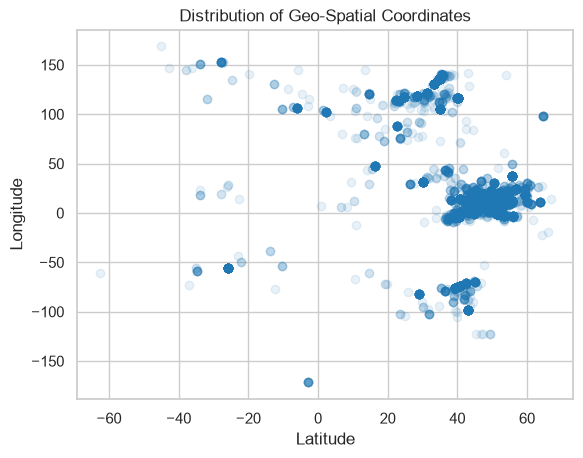

In [25]:
plt.title('Distribution of Geo-Spatial Coordinates')
plt.xlabel('Latitude')
plt.ylabel('Longitude')
plt.scatter(*zip(*ppnPosition),alpha=0.1)
if saveFiguresAsPDF:
    plt.savefig('./figures/sample_2026.pdf')

* Latitudes range from -90 to 90. -> x-Achse sollte 180 breit sein, Mitte ist 90
* Longitudes range from -180 to 180 -> y-Achse sollte 360 breit sein, Mitte ist 180


In [26]:
feats=ppnPosition

# define the number of clusters to be found
true_k=30
printLog("Clustering of %i elements started with %i as cluster target size."%(len(feats),true_k))
# initialize the k-means algorithm
#km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
# we will rely on the mini batch k-means algorithm due to performance consideration otherwise your computer might crash...
km = MiniBatchKMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)

# apply the algorithm on the data
km.fit(feats)
printLog("Clustering finished.")
km.labels_

[2026-10-30 22:41:10.841200]	Clustering of 85211 elements started with 30 as cluster target size.
[2026-10-30 22:41:10.885818]	Clustering finished.


array([29,  2,  5, ..., 12,  5, 21], shape=(85211,), dtype=int32)

bounding boxes aus http://boundingbox.klokantech.com/

Visualization with GeoJSON (http://geojson.org/) https://pypi.python.org/pypi/geojson and OpenLayers  http://openlayers.org/en/latest/doc/ http://openlayers.org/en/latest/apidoc/




In [27]:
regions=["Europe","Africa","Asia","Australia","SouthAmerica","NorthAmerica"]
regionBoundingBox=dict()
#westlimit=-22.5; southlimit=33.6; eastlimit=58.4; northlimit=82.9
regionBoundingBox["Europe"]=[33.6,82.9,-22.5,58.4]
#africa westlimit=-22.9; southlimit=-63.7; eastlimit=58.0; northlimit=37.2
regionBoundingBox["Africa"]=[-63.7,37.2,-22.9,58.0]
#asia westlimit=29.5; southlimit=-11.4; eastlimit=-168.4; northlimit=81.2
regionBoundingBox["Asia"]=[-11.4,81.2,-168.4,29.5]
#australia westlimit=112.5; southlimit=-50.4; eastlimit=-162.9; northlimit=-10.0
regionBoundingBox["Australia"]=[-50.4,-10.0,-162.9,112.5]
#south america westlimit=-119.5; southlimit=-57.0; eastlimit=-29.9; northlimit=28.1
regionBoundingBox["SouthAmerica"]=[-57.0,28.1,-119.5,-29.9]
#north america westlimit=-169.1; southlimit=23.7; eastlimit=-20.0; northlimit=71.4
regionBoundingBox["NorthAmerica"]=[23.7,71.4,-169.1,-20.0]


# man muss checken in welchen intervallen die kontinente liegen, insb. bei 2 und 3
def getRegion(lat,lng):
    for region in regions:
        if region in regionBoundingBox:
            if regionBoundingBox[region][0] <= lat <= regionBoundingBox[region][1]:
                if regionBoundingBox[region][2] <= lng <= regionBoundingBox[region][3]:
                    return region

    return "other"

#print getRegion(51,10)



In [28]:
# combine all arrays and check if there is more than one location associated with a PPN
# ppnPosition is (lat,lng)
printLog("Creating GeoJSON data...")
multipleCitiesPPN=pickleDecompress("./picklez/multipleSpatialNamesPerPPN.picklez")

baseDir="./web/data_2026/layers/"
if not os.path.exists(baseDir):
        os.makedirs(baseDir)
        
fileName=baseDir+"test.json"
locationFeatures=dict()
locationFeaturesGlobal=[]

spots=zip(ppnPositionLabels, ppnPositionSpatialClean,ppnPosition)

for spot in spots:
    ppn=spot[0]
    leadingLoc=spot[1]
    latLng=spot[2]
    # GeoJSON points are in longitude , latitude but our storage is lat/lng
    my_point = gj.Point((latLng[1], latLng[0]))

    region=getRegion(latLng[0],latLng[1])
    if region not in locationFeatures:
        locationFeatures[region]=[]
        print("Adding "+region)
    else:
        locationFeatures[region].append(gj.Feature(geometry=my_point, properties={"title": leadingLoc+" "+ppn, "ppn":ppn}))
    
    locationFeaturesGlobal.append(gj.Feature(geometry=my_point, properties={"title": leadingLoc+" "+ppn, "ppn":ppn}))
    #print ppn
    if ppn in multipleCitiesPPN:
        array=multipleCitiesPPN[ppn]
        #if there are alternative locations for this PPN
        if len(array)>1:
            #print leadingLoc+" "+ppn
            #print "\t"+"; ".join(array).encode("utf-8")
            pass

for region in locationFeatures:
    geoJSON_collection=gj.FeatureCollection(locationFeatures[region])
    dump = gj.dumps(geoJSON_collection, sort_keys=True)

    jsonFile = open(baseDir+region.lower()+".json", "w")
    jsonFile.write(dump)
    jsonFile.close()
    

geoJSON_collection=gj.FeatureCollection(locationFeaturesGlobal)
dump = gj.dumps(geoJSON_collection, sort_keys=True)

globalJSONPath=baseDir+"global.json"
jsonFile = open(globalJSONPath, "w")
jsonFile.write(dump)
jsonFile.close()
printLog("Serialized %i metadata records.\n\tSaved global JSON document at %s." %(len(locationFeaturesGlobal),globalJSONPath))

printLog("Done.")

[2026-10-30 22:41:10.904030]	Creating GeoJSON data...
[2026-10-30 22:41:10.904752]	Depickling from './picklez/multipleSpatialNamesPerPPN.picklez'
[2026-10-30 22:41:10.952088]	Depickling done.
Adding Europe
Adding Asia
Adding Australia
Adding other
Adding Africa
[2026-10-30 22:41:12.352008]	Serialized 85211 metadata records.
	Saved global JSON document at ./web/data_2026/layers/global.json.
[2026-10-30 22:41:12.352818]	Done.


In [29]:
#print spots.index("PPN766441857")
#print(spots[10])
#print(getRegion(spots[10][2][0],spots[10][2][1]))

In [30]:
# we will create an inverted mapping from alternative location names to "leading" location names
# the resulting dicts "main" key will be the leading character of the alternative location name 
# within this map will be a mapping to the "leading" location name, e.g., 'Corfu' would be mapped to 'Korfu'
# lastLetter=r[0].lower()
osmNames=pickleDecompress('./picklez/osm_names.picklez')
osmAlternativesSorted=dict()
for leadLoc in osmNames:
    #print leadLoc
    for v in osmNames[leadLoc].values():
        leadingLetter=v[0].lower()
        if not leadingLetter in osmAlternativesSorted:
            osmAlternativesSorted[leadingLetter]=dict()
        else:
            osmAlternativesSorted[leadingLetter][v]=leadLoc

[2026-10-30 22:41:12.364344]	Depickling from './picklez/osm_names.picklez'
[2026-10-30 22:41:12.383213]	Depickling done.


In [31]:
# osmNames(key): alle alternativen titel in der Form names[loc][u'name']:
# u'Ems': {u'name:nl': u'Eems', u'name': u'Ems', u'name:de': u'Ems', u'name:la': u'Amisia'...
# latLng(key)[lat|lng]: latitude/longitude pro key

# Service Functions
to avoid problems with JSON access you should load the web pages from your own HTTP server

In [ ]:
# debug HTTP server
#import importlib
#importlib.reload(http_server) # force reload of the module to avoid caching issues
#if True:

if launchHTTPServer:
    # the resulting HTTP service will listen on port 8000 and open the main page in the browser
    import http_server
    http_server.stop()
    http_server.load_url('web/webapps/index.html')

Webserver working directory: /Users/david/src/SBBrowse2018
To restart server run: 
python -m http.server 8000
